In [1]:
from google.colab import files
uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (768, 9)

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


Data Inspection and Preprocessing

In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

print("\nOutcome distribution:")
print(df["Outcome"].value_counts())

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome             

In [5]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("Missing values after replacing invalid zeros:")
print(df.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Model Training Using Logistic Regression

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model training completed successfully!
Training samples: 614
Testing samples: 154


Model Evaluation

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test,y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.734
Precision: 0.603
Recall: 0.704
F1-score: 0.65
ROC-AUC: 0.813

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



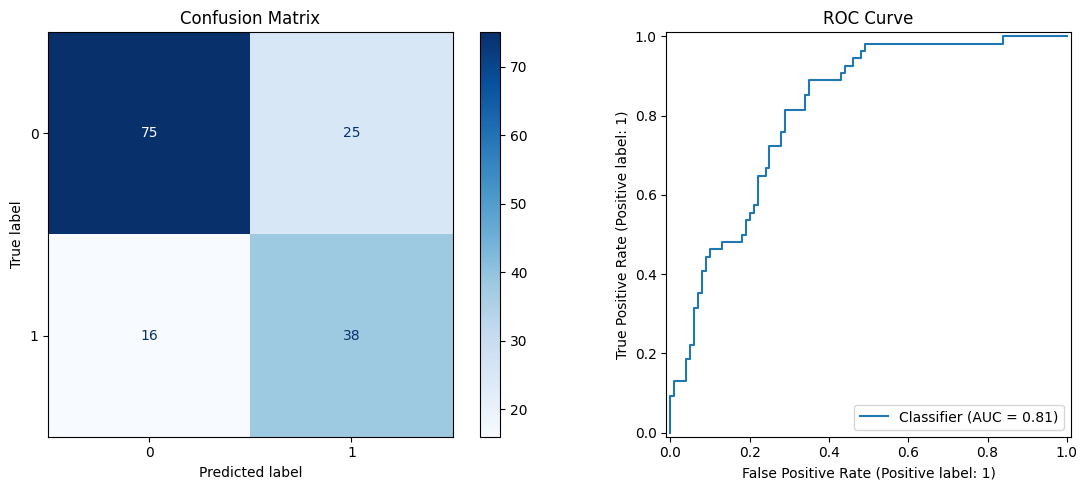

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test, y_prob,
    ax=axes[1]
)
axes[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()

In [15]:

# Coefficient Interpretation

# Extract feature names and coefficients from the trained model
feature_names = X_train.columns
coefficients = model.named_steps["classifier"].coef_[0]

# Create a table of coefficients
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient strength
coefficient_table["Absolute Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("Logistic Regression Coefficients:")
display(coefficient_table.round(3))

print("\nInterpretation:")
print("Positive coefficients push predictions towards Outcome = 1.")
print("Negative coefficients push predictions towards Outcome = 0.")
print("Larger absolute values indicate stronger influence on the")
print("model's predictions when features are standardized.")


Logistic Regression Coefficients:


,Feature,Coefficient,Absolute Coefficient
1,Glucose,1.183,1.183
5,BMI,0.710,0.710
0,Pregnancies,0.373,0.373
6,DiabetesPedigreeFunction,0.288,0.288
7,Age,0.186,0.186
4,Insulin,-0.045,0.045
2,BloodPressure,-0.015,0.015
3,SkinThickness,0.014,0.014



Interpretation:
Positive coefficients push predictions towards Outcome = 1.
Negative coefficients push predictions towards Outcome = 0.
Larger absolute values indicate stronger influence on the
model's predictions when features are standardized.


#                   Conclusion

In this project, I developed a Logistic Regression model to classify diabetes outcomes using the Pima Indians Diabetes dataset. The data was inspected and preprocessed using median imputation and standardization. The model was evaluated using accuracy, precision recall, F1-score, ROC-AUC, and a confusion matrix. The results show how machine learning can be used for a binary classification task. However, the dataset is limited,and the model is intended for educational purposes rather than medical diagnosis.